# Project 3: Weather Snapshot — Mumbai, 2025

## Project question
How did temperature and precipitation vary through the year in Mumbai?

This notebook explores daily weather records for one location and one calendar year. It checks the data, compares monthly patterns, and uses charts to make those patterns easier to see. The analysis is descriptive; it is not a forecast or a long-term climate study.

## 1. Load and inspect the data

The input file is `Mumbai_Weather_2025.csv`. Its first three lines contain metadata, so they are skipped when the table is read. The date column is converted to a date type before analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load daily records and parse the date column.
df = pd.read_csv("Mumbai_Weather_2025.csv", skiprows=3)
df["time"] = pd.to_datetime(df["time"])

print(f"Rows and columns: {df.shape}")
display(df.head())

Rows and columns: (365, 4)


,time,temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm)
0,2025-01-01,32.4,22.3,0.0
1,2025-01-02,32.8,21.1,0.0
2,2025-01-03,33.4,21.1,0.0
3,2025-01-04,33.1,19.1,0.0
4,2025-01-05,29.3,21.2,0.0


## 2. Check data quality and date coverage

These checks report missing values, exact duplicate rows, repeated dates, column types, and whether every date in 2025 is represented. The notebook does not silently fill or remove records.

In [2]:
print("Missing values by column:")
display(df.isna().sum().rename("missing_values").to_frame())

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["time"].dt.normalize().duplicated().sum())
print("Column types:")
display(df.dtypes.rename("dtype").to_frame())

Missing values by column:


,missing_values
time,0
temperature_2m_max (°C),0
temperature_2m_min (°C),0
precipitation_sum (mm),0


Exact duplicate rows: 0
Duplicate dates: 0
Column types:


,dtype
time,datetime64[us]
temperature_2m_max (°C),float64
temperature_2m_min (°C),float64
precipitation_sum (mm),float64


In [14]:
expected_dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
actual_dates = pd.DatetimeIndex(df["time"].dt.normalize().drop_duplicates())
missing_dates = expected_dates.difference(actual_dates)
outside_dates = actual_dates[
    (actual_dates < pd.Timestamp("2025-01-01")) | (actual_dates > pd.Timestamp("2025-12-31"))
]

if len(missing_dates) == 0:
    print("All dates in 2025 are present.")
else:
    print("Missing dates:")
    print(missing_dates)

if len(outside_dates) == 0:
    print("No dates outside 2025.")
else:
    print("Dates outside 2025:")
    print(outside_dates)

All dates in 2025 are present.
No dates outside 2025.


## 3. Prepare month labels

Each daily record receives a month name. An ordered month category keeps monthly summaries and charts in calendar order rather than alphabetical order.

In [4]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
df["Month"] = pd.Categorical(
    df["time"].dt.month_name(),
    categories=month_order,
    ordered=True
)

## 4. Build the monthly summary

For each month, calculate total precipitation, average and median daily minimum and maximum temperatures, and the within-month range of the daily minimum and maximum series. Temperature is in °C and precipitation is in mm.

In [15]:
monthly_summary = df.groupby("Month", observed=True).agg(
    total_rainfall_mm=("precipitation_sum (mm)", "sum"),
    average_daily_minimum_c=("temperature_2m_min (°C)", "mean"),
    average_daily_maximum_c=("temperature_2m_max (°C)", "mean"),
    median_daily_minimum_c=("temperature_2m_min (°C)", "median"),
    median_daily_maximum_c=("temperature_2m_max (°C)", "median")
)

monthly_summary["max_temp_range_c"] = (
    df.groupby("Month", observed=True)["temperature_2m_max (°C)"].max()
    - df.groupby("Month", observed=True)["temperature_2m_max (°C)"].min()
)
monthly_summary["min_temp_range_c"] = (
    df.groupby("Month", observed=True)["temperature_2m_min (°C)"].max()
    - df.groupby("Month", observed=True)["temperature_2m_min (°C)"].min()
)

monthly_summary.round(2)

,total_rainfall_mm,average_daily_minimum_c,average_daily_maximum_c,median_daily_minimum_c,median_daily_maximum_c,max_temp_range_c,min_temp_range_c
Month,,,,,,,
January,0.0,20.88,31.64,20.90,31.50,5.4,4.4
February,0.0,22.18,33.84,22.15,34.35,8.6,5.4
March,0.0,24.28,34.80,24.30,35.00,8.2,4.3
April,1.7,25.87,34.04,25.90,33.30,6.7,3.3
May,184.2,26.25,31.99,26.00,32.50,6.7,6.1
June,701.5,25.65,29.67,25.50,29.55,4.6,4.4
July,516.7,25.28,28.18,25.40,28.10,2.3,2.0
August,641.5,25.05,27.93,25.00,28.20,3.3,1.2
September,466.9,24.61,28.18,24.65,28.30,3.3,1.3


## 5. Monthly precipitation

The bar chart compares total recorded precipitation for each month.

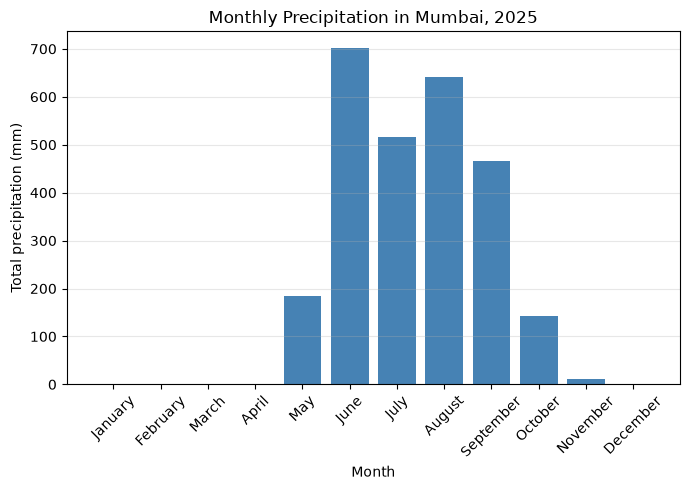

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(monthly_summary.index, monthly_summary["total_rainfall_mm"], color="steelblue")
ax.set_xlabel("Month")
ax.set_ylabel("Total precipitation (mm)")
ax.set_title("Monthly Precipitation in Mumbai, 2025")
ax.tick_params(axis="x", labelrotation=45)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Daily temperatures and 7-day averages

The solid lines show each day's maximum and minimum temperatures. Dashed lines show their 7-day rolling averages, which smooth short-term fluctuations. The first six days have no rolling-average value because a full seven-day window is not yet available.

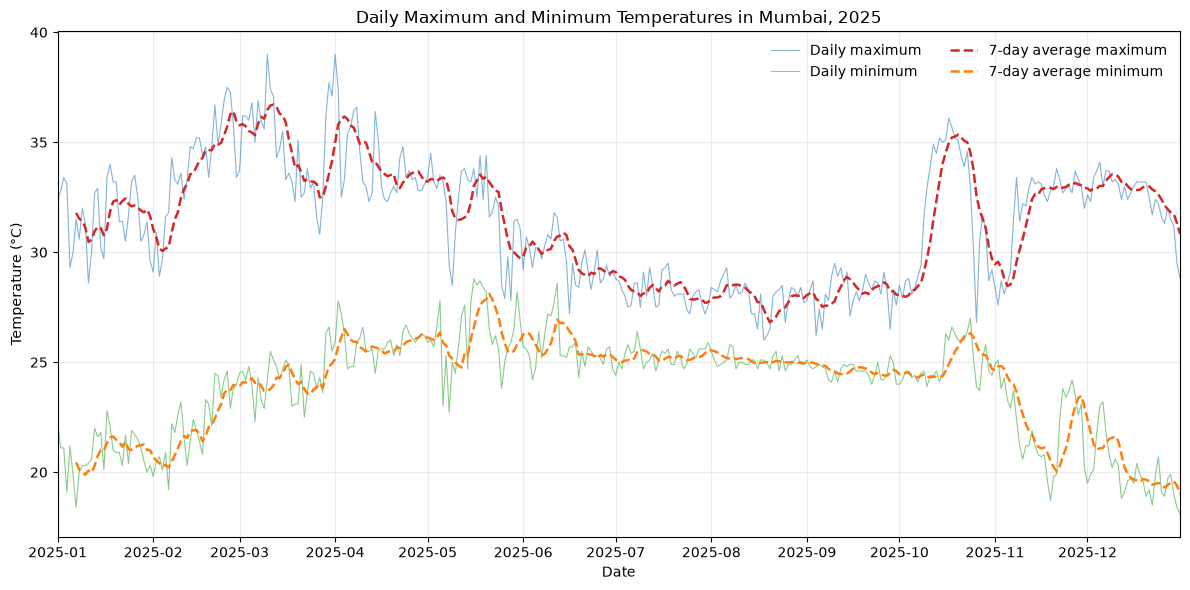

In [23]:
df["max_temp_7day_avg"] = df["temperature_2m_max (°C)"].rolling(window=7).mean()
df["min_temp_7day_avg"] = df["temperature_2m_min (°C)"].rolling(window=7).mean()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df["time"], df["temperature_2m_max (°C)"], color="tab:blue", alpha=0.55,
        linewidth=0.8, label="Daily maximum")
ax.plot(df["time"], df["temperature_2m_min (°C)"], color="tab:green", alpha=0.55,
        linewidth=0.8, label="Daily minimum")
ax.plot(df["time"], df["max_temp_7day_avg"], color="tab:red", linestyle="--",
        linewidth=1.8, label="7-day average maximum")
ax.plot(df["time"], df["min_temp_7day_avg"], color="tab:orange", linestyle="--",
        linewidth=1.8, label="7-day average minimum")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily Maximum and Minimum Temperatures in Mumbai, 2025")
ax.set_xlim(df["time"].min(), df["time"].max())
ax.grid(alpha=0.25)
ax.legend(ncol=2, frameon=False)
fig.tight_layout()
plt.show()

## 7. Findings

- June had the highest monthly precipitation total at **701.5 mm**. January, February, March, and December each recorded **0.0 mm**.
- March had the highest monthly average daily maximum temperature, about **34.80°C**. August had the lowest, about **27.93°C**.
- May had the highest monthly average daily minimum temperature, about **26.25°C**. December had the lowest, about **19.94°C**.

## Limitation

This analysis covers one location and one year. It describes the records in this dataset and cannot establish a long-term climate trend or explain why the observed patterns occurred.